# 01 - Data preparation  (RUN ON: **Google Colab**)

**Goal:** download the Kaggle dataset, explore it, validate pre-processing, preview augmentation, create the
reproducible **70 % / 15 % / 15 %** split, verify it, and produce a bundle to move to the DGX B200.

| Step | What happens | Output |
|---|---|---|
| 1 | Download the dataset (public Kaggle data) | dataset folder |
| 2 | Exploration | tables and sample images |
| 3 | Pre-processing validation | corrupt-file check, size statistics, tensor check |
| 4 | Augmentation preview | augmented examples |
| 5 | Split + verification (seed 42) | `data/splits/{train,validation,test}.csv`, `split_manifest.json` |
| 6 | Leakage audit | random vs time-block similarity |
| 7 | Transfer bundle | `fruit_data_bundle.zip` (downloaded to your computer) |

Runtime: a normal CPU runtime is enough (no GPU needed). Training happens later on the DGX (notebook 02).
Nothing is saved to Google Drive - files stay on the Colab disk and are downloaded to **your computer** in step 7.

In [1]:
# ===== SETUP - run this cell first =====
import os, subprocess, sys
from pathlib import Path

# Colab only: put your GitHub repo URL here, OR leave "" and upload + unzip the project zip to /content
REPO_URL = ""

IN_COLAB = "google.colab" in sys.modules
PROJECT_DIR = Path("/home/jovyan/work/onkar1/fresh-rotten-fruit-capstone")
ZIP = Path("/content/fresh-rotten-fruit-capstone.zip")      # Colab: the project zip you uploaded to the Files panel
if not (PROJECT_DIR / "src").exists() and ZIP.exists():
    import shutil; shutil.unpack_archive(str(ZIP), "/content")
if not (PROJECT_DIR / "src").exists():
    if REPO_URL:
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
    else:
        raise SystemExit(f"Project folder not found: {PROJECT_DIR}. Upload fresh-rotten-fruit-capstone.zip to /content (Files panel) or set REPO_URL above, then re-run.")
if IN_COLAB and os.getenv("FRUIT_SKIP_PIP") != "1":
    # Colab already has TensorFlow/pandas/scikit-learn; only the extras are installed (never reinstall TensorFlow).
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_DIR / "requirements-colab.txt")], check=True)
sys.path.insert(0, str(PROJECT_DIR / "src"))
os.chdir(PROJECT_DIR)

from fruitfresh import config
print("Project:", PROJECT_DIR, "| split dir:", config.DEFAULT_SPLIT_DIR, "| work dir:", config.DEFAULT_WORK_DIR)

Project: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone | split dir: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/data/splits | work dir: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/workspace


## 1. Download the dataset
Uses `kagglehub` (the dataset is public). On a machine that already has the data, set the environment variable `FRUIT_DATA_ROOT` instead.

In [2]:
from fruitfresh.data_index import get_dataset_root
DATA_ROOT = get_dataset_root()
print("Dataset root:", DATA_ROOT)
print(sorted(p.name for p in DATA_ROOT.iterdir()))

Dataset root: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/data/raw
['dataset', 'test', 'train']


## 2. Exploration
`build_index` reads every file name and records: class, **source photo** (`source_id`), whether the file is an original or an
augmented copy (file-name prefixes such as `rotated_by_15_`), and the capture time stored in the screenshot name.
Files that are byte-identical copies in both Kaggle folders are removed.

In [3]:
import json, pandas as pd
import matplotlib.pyplot as plt
from fruitfresh.data_index import build_index, summarize_index

index = build_index(DATA_ROOT)
summary = summarize_index(index)
print(json.dumps(summary, indent=2))
index.head()

{
  "n_images": 13599,
  "n_sources": 1511,
  "share_original_images": 0.1111111111111111,
  "n_original_images": 1511,
  "sources_in_both_kaggle_folders": 1310,
  "sources_with_timestamp": 1511,
  "capture_dates": [
    "2018-06-07",
    "2018-06-08",
    "2018-06-12",
    "2018-06-13"
  ],
  "augmentation_types": {
    "rotated_by_N": 7555,
    "saltandpepper": 1511,
    "translation": 1511,
    "vertical_flip": 1511
  },
  "exact_duplicates_dropped": 0
}


,image_path,kaggle_folder,class_name,file_name,base_name,aug_type,is_original,capture_time,source_id,has_timestamp,label
0,train/freshapples/Screen Shot 2018-06-08 at 4....,train,freshapples,Screen Shot 2018-06-08 at 4.59.36 PM.png,Screen Shot 2018-06-08 at 4.59.36 PM.png,,True,2018-06-08 16:59:36,freshapples/Screen Shot 2018-06-08 at 4.59.36 ...,True,0
1,train/freshapples/Screen Shot 2018-06-08 at 4....,train,freshapples,Screen Shot 2018-06-08 at 4.59.49 PM.png,Screen Shot 2018-06-08 at 4.59.49 PM.png,,True,2018-06-08 16:59:49,freshapples/Screen Shot 2018-06-08 at 4.59.49 ...,True,0
2,train/freshapples/Screen Shot 2018-06-08 at 4....,train,freshapples,Screen Shot 2018-06-08 at 4.59.57 PM.png,Screen Shot 2018-06-08 at 4.59.57 PM.png,,True,2018-06-08 16:59:57,freshapples/Screen Shot 2018-06-08 at 4.59.57 ...,True,0
3,train/freshapples/Screen Shot 2018-06-08 at 5....,train,freshapples,Screen Shot 2018-06-08 at 5.00.03 PM.png,Screen Shot 2018-06-08 at 5.00.03 PM.png,,True,2018-06-08 17:00:03,freshapples/Screen Shot 2018-06-08 at 5.00.03 ...,True,0
4,train/freshapples/Screen Shot 2018-06-08 at 5....,train,freshapples,Screen Shot 2018-06-08 at 5.00.12 PM.png,Screen Shot 2018-06-08 at 5.00.12 PM.png,,True,2018-06-08 17:00:12,freshapples/Screen Shot 2018-06-08 at 5.00.12 ...,True,0


is_original,augmented copy,original,All
class_name,,,
freshapples,1856,232,2088
freshbanana,1744,218,1962
freshoranges,1648,206,1854
rottenapples,2616,327,2943
rottenbanana,2448,306,2754
rottenoranges,1776,222,1998
All,12088,1511,13599


kaggle_folder,test,train,All
class_name,,,
freshapples,395,1693,2088
freshbanana,381,1581,1962
freshoranges,388,1466,1854
rottenapples,601,2342,2943
rottenbanana,530,2224,2754
rottenoranges,403,1595,1998
All,2698,10901,13599


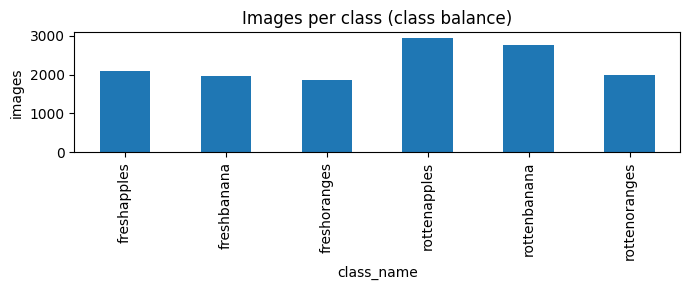

In [8]:
display(pd.crosstab(index.class_name, index.is_original.map({True: "original", False: "augmented copy"}), margins=True))
display(pd.crosstab(index.class_name, index.kaggle_folder, margins=True))
counts = index.class_name.value_counts().reindex(config.CLASS_NAMES)
counts.plot.bar(figsize=(7, 3), title="Images per class (class balance)"); plt.ylabel("images"); plt.tight_layout(); plt.show()

**Read this:** the number of *source photos* is much smaller than the number of *files*. That is why the split below is done on source photos.

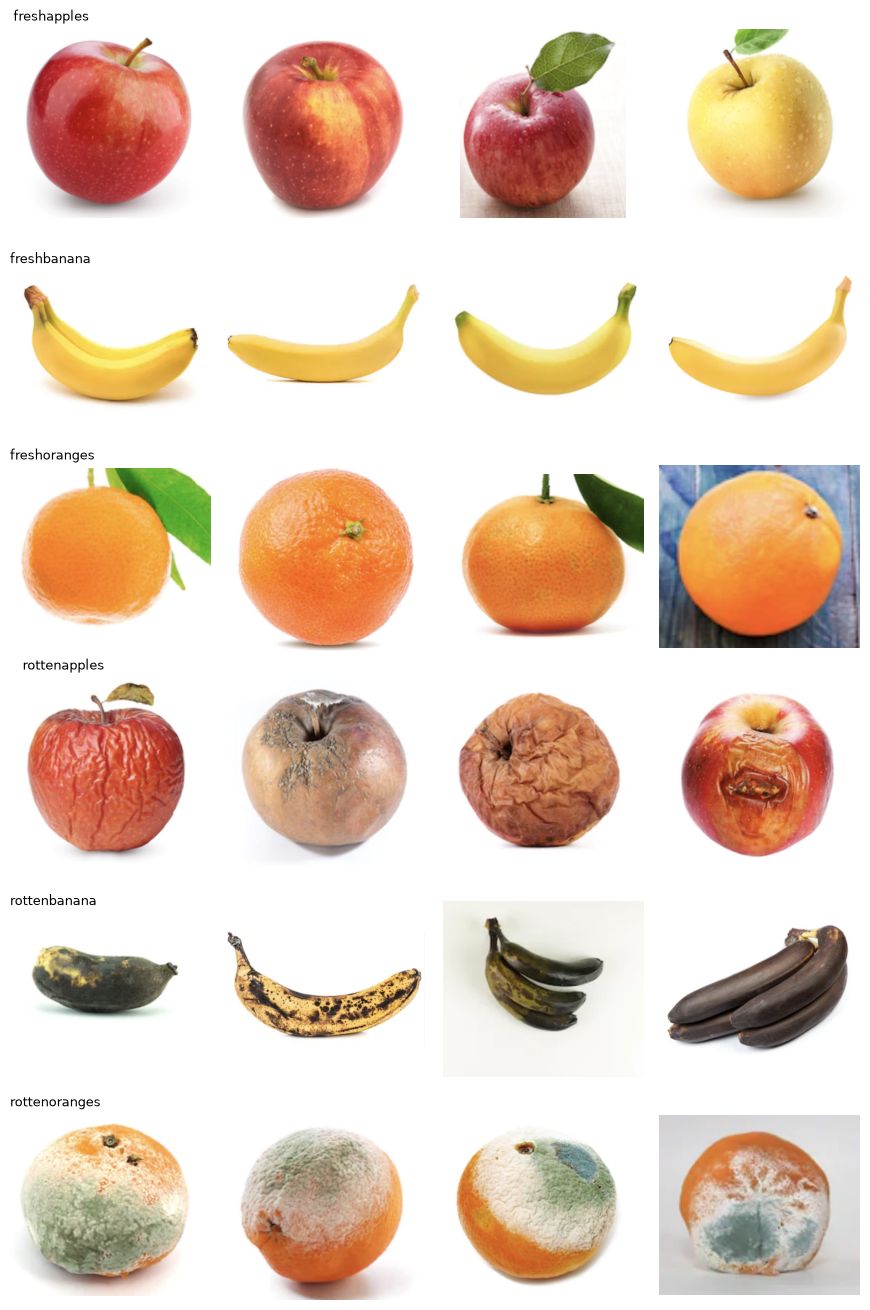

In [4]:
from fruitfresh.viz import sample_grid
sample_grid(index, DATA_ROOT, per_class=4); plt.show()

## 3. Pre-processing validation

In [5]:
from PIL import Image
from fruitfresh.data_index import find_unreadable
bad = find_unreadable(index, DATA_ROOT)
print("Unreadable / corrupt images:", len(bad), bad[:5])

sample = index.sample(min(300, len(index)), random_state=0)
sizes, modes = [], {}
for p in sample.image_path:
    with Image.open(DATA_ROOT / p) as im:
        sizes.append(im.size); modes[im.mode] = modes.get(im.mode, 0) + 1
sz = pd.DataFrame(sizes, columns=["width", "height"])
print("Image modes (RGBA/L are converted to RGB by the pipeline):", modes)
display(sz.describe().round(0))

Unreadable / corrupt images: 0 []
Image modes (RGBA/L are converted to RGB by the pipeline): {'RGB': 268, 'RGBA': 32}


,width,height
count,300.0,300.0
mean,415.0,356.0
std,125.0,74.0
min,146.0,116.0
25%,336.0,316.0
50%,398.0,362.0
75%,478.0,410.0
max,796.0,496.0


In [6]:
import sys
print("Notebook Python:", sys.executable)

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__)
except ImportError as e:
    print("TensorFlow unavailable:", e)

Notebook Python: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/.venv/bin/python


I0000 00:00:1792929461.280843  138766 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792929461.506810  138766 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792929473.115082  138766 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0


In [7]:
import numpy as np
from fruitfresh.datasets import make_dataset
tiny = index.sample(8, random_state=1)
x, y = next(iter(make_dataset(tiny, DATA_ROOT, batch_size=8, cache=False)))
print("Batch:", x.shape, x.dtype, "| pixel range", float(x.numpy().min()), "-", float(x.numpy().max()), "| labels", y.numpy())
assert x.shape == (8, *config.IMAGE_SIZE, 3) and x.numpy().max() <= 255   # models rescale inside themselves
print("Pre-processing OK: every image -> 224x224x3 float32 (0..255); each model normalises internally.")

Batch: (8, 224, 224, 3) <dtype: 'float32'> | pixel range 0.0 - 255.0 | labels [0 2 1 2 4 0 1 4]
Pre-processing OK: every image -> 224x224x3 float32 (0..255); each model normalises internally.


W0000 00:00:1792929497.964932  138766 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1792929497.983111  138766 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1792929498.000631  138766 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1792929498.803051  138766 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1792929498.817131  138766 gpu_device.cc:2459] Tensor

## 4. Augmentation set-up (preview)
Random flips, rotation, zoom, translation, brightness and contrast are applied **only to training batches** during training.

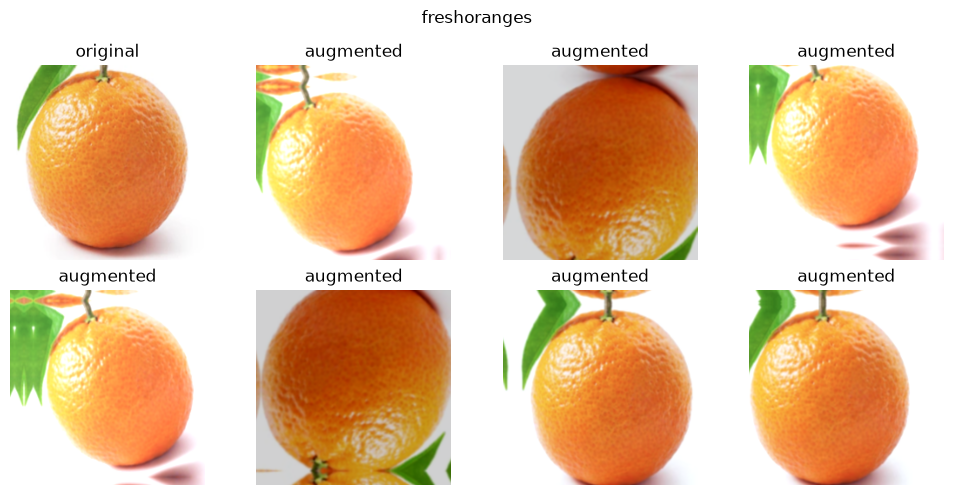

In [8]:
import tensorflow as tf
from fruitfresh.datasets import build_augmenter
orig = index[index.is_original].sample(1, random_state=3).iloc[0]
img = np.array(Image.open(DATA_ROOT / orig.image_path).convert("RGB").resize(config.IMAGE_SIZE))[None].astype("float32")
aug = build_augmenter(seed=1)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes[0, 0].imshow(img[0].astype("uint8")); axes[0, 0].set_title("original")
for ax in axes.ravel()[1:]:
    ax.imshow(np.clip(aug(img, training=True)[0].numpy(), 0, 255).astype("uint8")); ax.set_title("augmented")
for ax in axes.ravel(): ax.axis("off")
plt.suptitle(orig.class_name); plt.tight_layout(); plt.show()

## 5. Reproducible 70 / 15 / 15 split
Method (details in `docs/METHODOLOGY.md`): all copies of a source photo stay together; source photos of each class are ordered by capture
time, cut into blocks, whole blocks go to train / validation / test, and a 60-second buffer is left between splits. Seed 42.
The final image percentages differ slightly from 70/15/15 because the buffer removes some photos and blocks are whole units.

In [9]:
from fruitfresh.splits import make_time_block_split, verify_split, save_split, load_split
SEED = config.SEED
index_split, split_report = make_time_block_split(index, seed=SEED, **config.SPLIT_PARAMS)
stats = verify_split(index_split, buffer_seconds=config.SPLIT_PARAMS["buffer_seconds"])   # raises if leaky
total = sum(stats["images"].values())
print("images :", stats["images"], {k: f"{v/total:.1%}" for k, v in stats["images"].items()})
print("sources:", stats["sources"])
print("dropped by the time buffer:", stats["n_sources_dropped"], "source photos")
print("smallest time gap between splits (same class):", stats["min_cross_split_gap_seconds"], "s")
display(pd.DataFrame(stats["images_per_class"]))
display(pd.DataFrame(stats["blocks_per_class"]).T)

images : {'train': 8280, 'validation': 1782, 'test': 1935} {'train': '69.0%', 'validation': '14.9%', 'test': '16.1%'}
sources: {'train': 920, 'validation': 198, 'test': 215}
dropped by the time buffer: 178 source photos
smallest time gap between splits (same class): 60.0 s


,train,validation,test
freshapples,1413,162,288
freshbanana,1053,387,225
freshoranges,1260,225,279
rottenapples,1800,342,468
rottenbanana,1458,441,450
rottenoranges,1296,225,225


,test,train,validation
freshapples,2,7,1
freshbanana,1,6,2
freshoranges,2,6,1
rottenapples,3,9,2
rottenbanana,2,9,2
rottenoranges,1,7,1


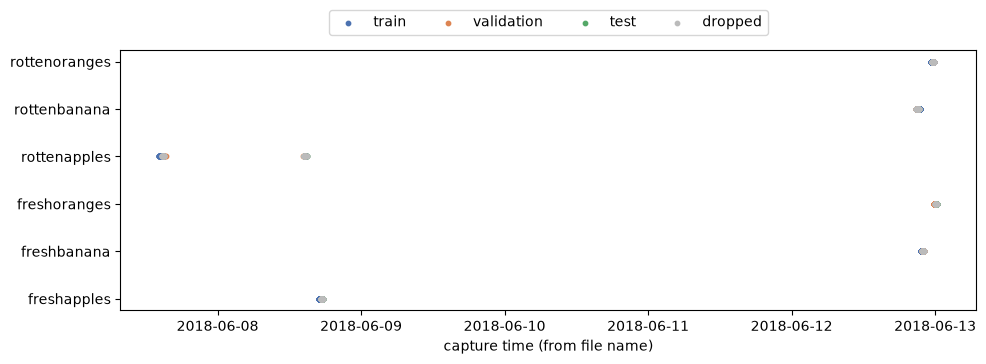

In [10]:
from fruitfresh.viz import split_timeline
split_timeline(index_split); plt.show()

## 6. Leakage audit (why not a random split?)

random split    : {'n': 227, 'median': 0.8613571524620056, 'mean': 0.834778368473053, 'share_above_0.95': 0.07048458149779736, 'share_above_0.98': 0.022026431718061675}
time-block split: {'n': 215, 'median': 0.8318642377853394, 'mean': 0.7980387210845947, 'share_above_0.95': 0.018604651162790697, 'share_above_0.98': 0.0}


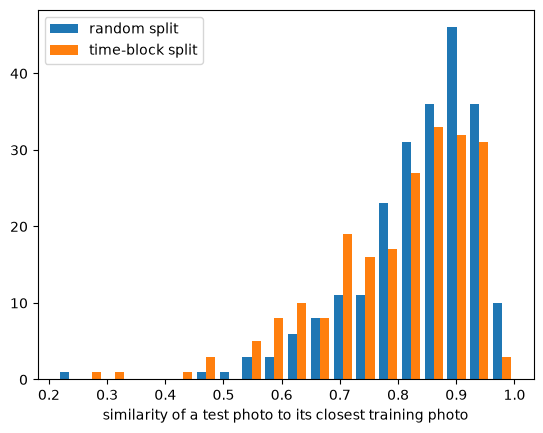

In [11]:
from fruitfresh.splits import make_random_group_split
from fruitfresh.audit import nearest_train_similarity, similarity_summary
s_random = nearest_train_similarity(make_random_group_split(index, seed=SEED), DATA_ROOT)
s_block = nearest_train_similarity(index_split, DATA_ROOT)
print("random split    :", similarity_summary(s_random))
print("time-block split:", similarity_summary(s_block))
plt.hist([s_random, s_block], bins=20, label=["random split", "time-block split"]); plt.legend()
plt.xlabel("similarity of a test photo to its closest training photo"); plt.show()

Report both numbers honestly. If the two splits look similar on this crude measure, say so; the time buffer is still the safer design.

## 7. Save the split and create the transfer bundle

In [12]:
manifest = save_split(index_split, config.DEFAULT_SPLIT_DIR, {**config.SPLIT_PARAMS, "seed": SEED, **split_report}, stats)
train_df, val_df, test_df = load_split(config.DEFAULT_SPLIT_DIR)       # re-load = checks the SHA-256 hashes
print("Saved to", config.DEFAULT_SPLIT_DIR, [len(train_df), len(val_df), len(test_df)])
print(json.dumps(manifest["files"], indent=2))

Saved to /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/data/splits [8280, 1782, 1935]
{
  "train.csv": "9c18e8d499edfdf38f9106927298881e8f3d44aad5cea5b05c9dfaba74aa6626",
  "validation.csv": "976098e1da161629f1dfd2e75ef9a8f77b325115b3e298347ee03b8b0e049f14",
  "test.csv": "c2ddddbc7890326942e3be9a03d76bad09eba667361b8ac3ae42688146998696"
}


In [13]:
# INCLUDE_IMAGES = True : the zip contains the images (use when the DGX has NO internet).
# INCLUDE_IMAGES = False: only the CSVs (small); the DGX downloads the images itself with scripts/download_dataset.py.
INCLUDE_IMAGES = True
from fruitfresh.transfer import make_data_bundle
bundle = make_data_bundle(DATA_ROOT, config.DEFAULT_SPLIT_DIR, PROJECT_DIR / "fruit_data_bundle.zip", include_images=INCLUDE_IMAGES)
print(f"{bundle}  ({bundle.stat().st_size/1e6:.0f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(str(bundle))          # saved through your browser to YOUR computer (not to Google Drive)

/home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/fruit_data_bundle.zip  (1708 MB)


### Transfer to the DGX B200
On your computer (replace user/host/path with your site's values):
```bash
scp fruit_data_bundle.zip <user>@<dgx-host>:<path-to-project>/
ssh <user>@<dgx-host>
cd <path-to-project> && unzip -o fruit_data_bundle.zip        # creates data/splits/ and (if included) data/raw/
python scripts/verify_data.py --split-dir data/splits --data-root data/raw   # must print DATA OK
```

In [14]:
assert (config.DEFAULT_SPLIT_DIR / "split_manifest.json").exists() and bundle.exists()
print("READY FOR THE DGX: split verified, bundle created. Continue with notebook 02 (or scripts/train.py) on the DGX.")

READY FOR THE DGX: split verified, bundle created. Continue with notebook 02 (or scripts/train.py) on the DGX.
